In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, chisquare
from statsmodels.stats.multitest import multipletests

# Upload file
df = pd.read_csv("cookie_cats.csv")

### **1. Data Understanding**

**Business Problem**

Cookie Cats đang thử nghiệm xem việc di chuyển ngưỡng tiến trình (gate) từ cấp độ 30 lên cấp độ 40 có cải thiện tỷ lệ giữ chân người chơi (retention) hay không. Đây là câu hỏi kinh điển trong thiết kế game: đặt gate sớm hơn buộc người chơi dừng lại chờ (thường để mời bạn bè hoặc chờ thời gian hồi) sớm hơn — điều này vừa có thể gây khó chịu, vừa có thể tạo ra "điểm nghỉ" giúp người chơi quay lại đều đặn hơn.

**Mục tiêu:** Đánh giá tác động của vị trí gate đến retention vào Ngày 1 (D1) và Ngày 7 (D7), từ đó đưa ra khuyến nghị nên giữ gate ở level 30 hay chuyển sang level 40.

In [38]:
# Data Overview
df.shape
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


**Nhận xét:** Dataset gồm 90,189 dòng và 5 cột:
- `userid`: định danh người chơi
- `version`: nhóm A/B (gate_30 / gate_40)
- `sum_gamerounds`: tổng số round đã chơi trong 14 ngày đầu
- `retention_1`, `retention_7`: có quay lại app vào ngày 1 / ngày 7 hay không (boolean)

Không có cột thời gian (timestamp) — đây là một giới hạn cần lưu ý xuyên suốt phân tích (không đánh giá được xu hướng theo thời gian hay novelty effect).

In [39]:
# Data Quality Check
df.isnull().sum()
df.duplicated().sum()
df['userid'].nunique()
df.shape[0] == df['userid'].nunique()

True

**Nhận xét:** Không có missing value, không có dòng trùng lặp, và số `userid` unique bằng đúng số dòng — nghĩa là mỗi user chỉ xuất hiện đúng 1 lần trong dataset. Data sạch ngay từ đầu, không cần xử lý (cleaning) thêm trước khi phân tích.

### **2. A/B Experiment Validation**

Trước khi so sánh retention giữa 2 nhóm, cần xác nhận rằng thí nghiệm được setup đúng: (1) người chơi được chia ngẫu nhiên với tỉ lệ hợp lý, và (2) hành vi chơi ban đầu của 2 nhóm là tương đương nhau. Nếu bỏ qua bước này, mọi khác biệt retention quan sát được về sau có thể chỉ phản ánh sự thiên lệch trong cách chia nhóm, chứ không phải do gate.

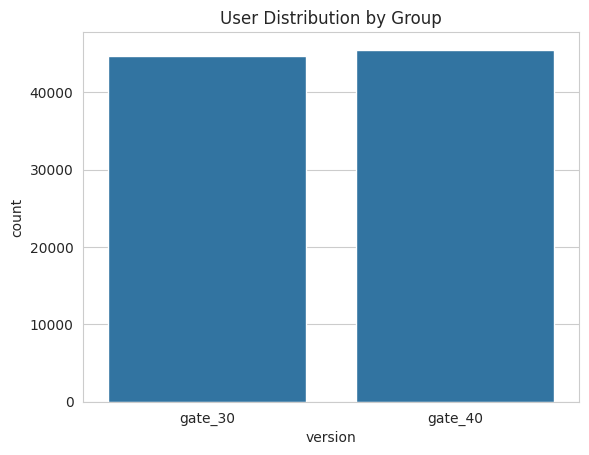

In [54]:
df['version'].value_counts()
df['version'].value_counts(normalize=True)

sns.countplot(data=df, x='version')
plt.title('User Distribution by Group')
plt.show()

**Nhận xét:** gate_30 = 44,700 users (49.6%), gate_40 = 45,489 users (50.4%). Nhìn bằng mắt thì tỉ lệ khá gần 50/50, nhưng "gần" không đồng nghĩa với "hợp lệ về mặt thống kê" — chênh lệch ~789 user vẫn có thể có ý nghĩa nếu kiểm định formal. Phần này sẽ được kiểm tra chặt chẽ bằng Sample Ratio Mismatch test ở mục 5.1, thay vì chỉ dừng ở quan sát trực quan như thế này.

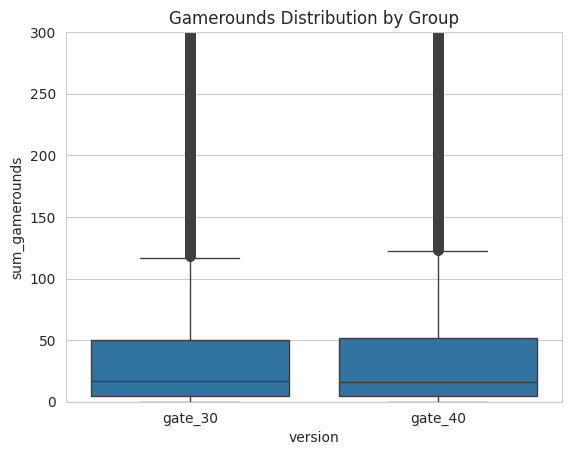

In [41]:
# So sánh engagement giữa 2 nhóm
df.groupby('version')['sum_gamerounds'].describe()

sns.boxplot(data=df, x='version', y='sum_gamerounds')
plt.ylim(0, 300)  # zoom lại vì có outlier cực lớn
plt.title('Gamerounds Distribution by Group')
plt.show()

**Nhận xét:** Median gamerounds của gate_30 là 17, gate_40 là 16 — gần như tương đương. Đây là dấu hiệu tốt cho thấy hành vi chơi ban đầu (trước khi bị ảnh hưởng bởi vị trí gate) của 2 nhóm là tương đồng, nên có thể so sánh retention giữa 2 nhóm một cách công bằng.

Đáng chú ý là có 1 outlier chơi tới 49,854 rounds (thuộc nhóm gate_30) — cao gấp hàng nghìn lần so với median. Giá trị này gần như chắc chắn là bot hoặc lỗi tracking chứ không phải hành vi người chơi thông thường. Outlier này không ảnh hưởng đến so sánh median ở đây, nhưng sẽ được kiểm tra kỹ hơn ở phần Sensitivity Analysis (mục 5.5) để đảm bảo nó không làm lệch kết luận cuối cùng.

### **3. Retention Analysis**

Đây là phần trung tâm của bài toán: so sánh trực tiếp tỉ lệ quay lại của người chơi giữa 2 phiên bản gate ở 2 mốc thời gian khác nhau. D1 phản ánh ấn tượng ban đầu, còn D7 phản ánh mức độ gắn bó dài hạn hơn — thường được xem là chỉ số quan trọng hơn trong ngành game.

version
gate_30    44.818792
gate_40    44.228275
Name: retention_1, dtype: float64


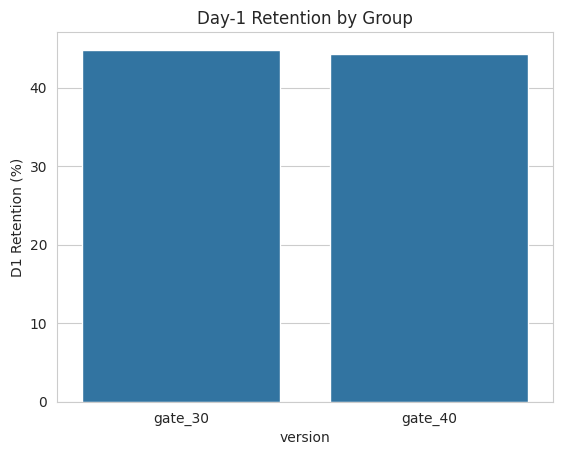

In [42]:
# Day-1 Retention
d1 = df.groupby('version')['retention_1'].mean() * 100
print(d1)

sns.barplot(x=d1.index, y=d1.values)
plt.ylabel('D1 Retention (%)')
plt.title('Day-1 Retention by Group')
plt.show()

**Nhận xét:** D1 retention của gate_30 là 44.82%, gate_40 là 44.23% — gate_30 cao hơn khoảng 0.59 điểm phần trăm (percentage point). Chênh lệch này khá nhỏ, và như sẽ thấy ở mục 5.3, chưa đủ để kết luận có ý nghĩa thống kê ở mốc D1. Điều này hợp lý về mặt trực giác: trong 1 ngày đầu, đa số người chơi còn chưa chạm tới gate (dù ở level 30 hay 40), nên vị trí gate chưa kịp tạo ra khác biệt rõ rệt.

version
gate_30    19.020134
gate_40    18.200004
Name: retention_7, dtype: float64


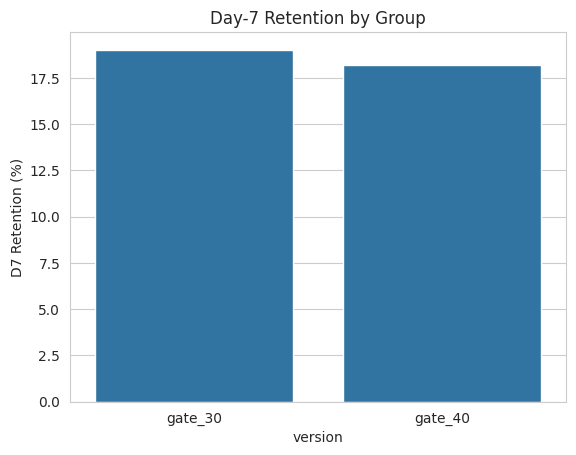

In [43]:
# Day-7 Retention
d7 = df.groupby('version')['retention_7'].mean() * 100
print(d7)

sns.barplot(x=d7.index, y=d7.values)
plt.ylabel('D7 Retention (%)')
plt.title('Day-7 Retention by Group')
plt.show()

**Nhận xét:** D7 retention của gate_30 là 19.02%, gate_40 là 18.20% — chênh lệch tăng lên khoảng 0.82 điểm phần trăm, lớn hơn so với D1. Điều này khớp với giả thuyết rằng sau 7 ngày, nhiều người chơi hơn đã chạm tới gate, nên tác động của vị trí gate lên quyết định "có quay lại hay không" bộc lộ rõ hơn. Đây là tín hiệu đầu tiên cho thấy D7 có thể là điểm khác biệt quan trọng hơn D1 — sẽ được xác nhận bằng kiểm định thống kê ở phần sau.

       Gate30     Gate40
D1  44.818792  44.228275
D7  19.020134  18.200004


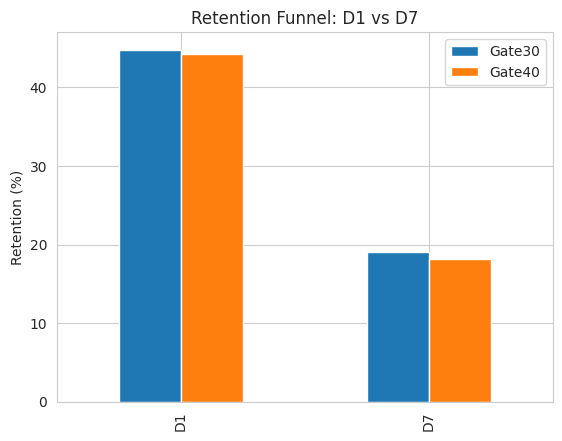

In [44]:
# Retention Funnel
funnel = pd.DataFrame({
    'Gate30': [d1['gate_30'], d7['gate_30']],
    'Gate40': [d1['gate_40'], d7['gate_40']]
}, index=['D1', 'D7'])
print(funnel)

funnel.plot(kind='bar')
plt.ylabel('Retention (%)')
plt.title('Retention Funnel: D1 vs D7')
plt.show()

**Nhận xét:** Nhìn theo funnel, cả 2 nhóm đều rơi rụng rất mạnh từ D1 sang D7 — mất hơn một nửa số user còn ở lại (gate_30: từ 44.82% xuống 19.02%; gate_40: từ 44.23% xuống 18.20%). Đây là mức độ churn khá điển hình với game mobile casual. Điểm quan trọng là gate_30 giữ chân tốt hơn ở cả 2 mốc, và khoảng cách giữa 2 nhóm còn *nới rộng* thêm theo thời gian thay vì thu hẹp lại — đây là dấu hiệu tích cực ủng hộ việc giữ gate ở level 30.

### **4. Behavioral Analysis**

Ngoài so sánh 2 nhóm A/B, cần hiểu thêm hành vi chơi tổng thể của toàn bộ user base — điều này giúp diễn giải kết quả retention có ý nghĩa hơn và phát hiện các đặc điểm dữ liệu cần lưu ý (outlier, phân phối lệch, nhóm hành vi khác biệt).

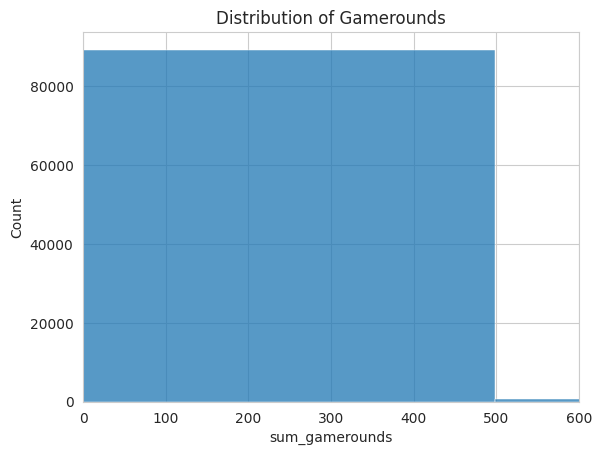

In [45]:
# Gamerounds Distribution
sns.histplot(df['sum_gamerounds'], bins=100)
plt.xlim(0, 600)  # cắt bớt để nhìn rõ phân phối chính
plt.title('Distribution of Gamerounds')
plt.show()

**Nhận xét:** Phân phối gamerounds lệch phải rất mạnh (right-skewed) — đa số user chơi rất ít (median chỉ ~16-17 rounds), trong khi một số ít "whale" chơi tới hàng nghìn, thậm chí gần 50,000 rounds. Đây là dạng phân phối phổ biến trong dữ liệu game/app: phần lớn user chỉ thử qua loa rồi bỏ, một nhóm nhỏ mới thực sự gắn bó lâu dài. Vì phân phối lệch mạnh, các thống kê dựa trên trung bình (mean) sẽ bị outlier kéo lệch — nên ưu tiên dùng median khi mô tả "hành vi điển hình", và cần xử lý riêng outlier khi tính toán ảnh hưởng đến kết luận (xem mục 5.5).

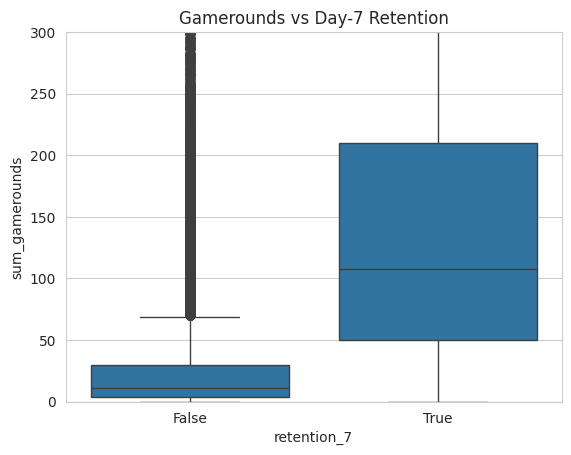

In [46]:
# Retention vs Engagement
df.groupby('retention_7')['sum_gamerounds'].median()

sns.boxplot(x='retention_7', y='sum_gamerounds', data=df)
plt.ylim(0, 300)
plt.title('Gamerounds vs Day-7 Retention')
plt.show()

**Nhận xét:** User không quay lại ở D7 có median chỉ 11 rounds, trong khi user quay lại ở D7 có median lên tới 108 rounds — chênh lệch gần 10 lần. Chơi nhiều rõ ràng đi kèm với giữ chân tốt hơn.

Tuy nhiên cần lưu ý đây chỉ là **tương quan (correlation)**, không phải quan hệ nhân quả (causation) đã được chứng minh. Có thể diễn giải theo 2 chiều: (1) chơi nhiều → thích game hơn → quay lại nhiều hơn, hoặc (2) người vốn thích thể loại game này ngay từ đầu → vừa chơi nhiều vừa có xu hướng quay lại, tức "sum_gamerounds" và "retention_7" cùng bị chi phối bởi một yếu tố tiềm ẩn (mức độ yêu thích game) chứ không nhất thiết cái này gây ra cái kia.

In [47]:
# Player Segmentation
def segment(x):
    if x < 50:
        return 'Casual'
    elif x < 200:
        return 'Mid-Core'
    else:
        return 'Hardcore'

df['segment'] = df['sum_gamerounds'].apply(segment)

pd.crosstab(df['segment'], df['retention_7'], normalize='index')

retention_7,False,True
segment,,
Casual,0.938201,0.061799
Hardcore,0.151176,0.848824
Mid-Core,0.543732,0.456268


**Nhận xét:** Chia user thành 3 nhóm theo mức độ chơi cho thấy bức tranh rõ hơn:
- Casual (< 50 rounds, 67,024 users, ~74% tổng user): chỉ 6.2% quay lại D7
- Mid-Core (50–200 rounds, 17,893 users, ~20%): 45.6% quay lại D7
- Hardcore (≥ 200 rounds, 5,272 users, ~6%): 84.9% quay lại D7

Retention gần như tăng tuyến tính theo mức độ engagement, và nhóm Hardcore giữ chân tốt gấp khoảng 14 lần so với nhóm Casual. Insight quan trọng ở đây cho product: phần lớn user (74%) thuộc nhóm Casual và gần như chắc chắn rời bỏ sớm — đây là nhóm mà việc tối ưu trải nghiệm ở những round đầu tiên (bao gồm cả vị trí gate) có khả năng tạo tác động lớn nhất, vì họ là nhóm đông nhất và cũng dễ mất nhất.

### **5. Statistical Testing & Validity**

Phần này trả lời câu hỏi cốt lõi: liệu chênh lệch retention quan sát được ở mục 3 có thực sự đến từ vị trí gate, hay chỉ là nhiễu ngẫu nhiên? Thứ tự các bước được sắp xếp có chủ đích: kiểm tra tính hợp lệ của thí nghiệm trước (5.1–5.2), rồi mới kiểm định giả thuyết chính (5.3), sau đó kiểm chứng lại độ tin cậy của kết quả bằng nhiều góc nhìn khác nhau (5.4–5.6) trước khi đưa ra kết luận cuối cùng.

#### 5.1 Data Validity Check — Sample Ratio Mismatch (SRM)

Trước khi tin bất kỳ so sánh retention nào, cần kiểm tra xem việc chia
random 2 nhóm có bị lệch (bias) không. Nếu tỉ lệ chia lệch khỏi 50/50 một
cách có ý nghĩa thống kê, mọi kết luận phía sau sẽ kém tin cậy hơn, bất kể
p-value của test retention là bao nhiêu — đây là bước kiểm tra được khuyến
nghị hàng đầu (nhưng thường bị bỏ qua) trong quy trình A/B testing chuẩn.

In [48]:
counts = df['version'].value_counts()
expected = [len(df)/2, len(df)/2]
chi2_srm, p_srm = chisquare(counts, f_exp=expected)

print(f"Observed: {counts.to_dict()}")
print(f"SRM chi2: {chi2_srm:.4f}, p-value: {p_srm:.4f}")

if p_srm < 0.05:
    print("⚠️ WARNING: Phát hiện Sample Ratio Mismatch. Cần lưu ý khi diễn giải kết quả.")
else:
    print("✅ Không phát hiện SRM. Quá trình phân tách hợp lệ.")

Observed: {'gate_40': 45489, 'gate_30': 44700}
SRM chi2: 6.9024, p-value: 0.0086
⚠️ WARNING: Phát hiện Sample Ratio Mismatch. Cần lưu ý khi diễn giải kết quả.


**Kết quả:** p = 0.0086 (< 0.05) → phát hiện SRM.

Tỉ lệ chia nhóm (49.6% / 50.4%) lệch khỏi 50/50 với ý nghĩa thống kê, dù
chênh lệch tuyệt đối chỉ khoảng 789 user. Với cỡ mẫu lớn (90,189 user), chi-square
test rất nhạy với những lệch nhỏ, nên statistically significant không đồng
nghĩa với "lệch nghiêm trọng về mặt thực tế".

Vì đây là dataset có sẵn nên không truy được nguyên nhân gây SRM. Nên tiếp tục phân tích, nhưng kết quả D7 được hiểu là "tín hiệu khá chắc chắn" chứ không phải "bằng chứng tuyệt đối".

#### 5.2 Data Quality — Nhóm user 0 rounds

In [49]:
zero_players = df[df['sum_gamerounds'] == 0]
print(f"Users with 0 gamerounds: {len(zero_players)} ({len(zero_players)/len(df)*100:.2f}%)")
print(zero_players[['retention_1', 'retention_7']].mean())

# Kiểm tra loại nhóm này có ảnh hưởng gì đến kết quả D7 test không
df_played = df[df['sum_gamerounds'] > 0]
t7_played = pd.crosstab(df_played['version'], df_played['retention_7'])
chi2_p, p_played, _, _ = chi2_contingency(t7_played)
print(f"D7 p-value excluding zero-round users: {p_played:.4f}")

Users with 0 gamerounds: 3994 (4.43%)
retention_1    0.021783
retention_7    0.007261
dtype: float64
D7 p-value excluding zero-round users: 0.0027


**Kết quả:** 4.43% user chưa từng chơi round nào — cài app rồi rời đi ngay. Retention của nhóm này gần như bằng 0 ở cả 2 gate (~2.2% D1, ~0.7% D7), nên họ không mang tín hiệu gì cho câu hỏi "gate ảnh hưởng thế nào" mà chỉ tạo noise.

Kiểm tra lại sau khi loại nhóm này, D7 p-value gần như không đổi so với mục 5.3. Vì vậy vẫn giữ nguyên toàn bộ dataset cho phân tích chính, để đơn giản và minh bạch.

#### 5.3 Hypothesis Test (Chi-square)

**Giả thuyết**

H0 (null hypothesis): Vị trí đặt gate không ảnh hưởng đến khả năng giữ chân người chơi.

H1 (alternative hypothesis): Vị trí đặt gate ảnh hưởng đến khả năng giữ chân người chơi.

Dùng chi-square test of independence vì cả `version` và `retention` đều là biến categorical (nhị phân).

In [50]:
# Test D1
table1 = pd.crosstab(df['version'], df['retention_1'])
chi2_1, p1, dof1, exp1 = chi2_contingency(table1)
print(f"D1 retention p-value: {p1:.4f}")

# Test D7
table7 = pd.crosstab(df['version'], df['retention_7'])
chi2_7, p7, dof7, exp7 = chi2_contingency(table7)
print(f"D7 retention p-value: {p7:.4f}")

D1 retention p-value: 0.0755
D7 retention p-value: 0.0016


**Kết quả:**

- D1: p = 0.0755 → p > 0.05 → chưa đủ bằng chứng thống kê để bác bỏ H0. Chênh lệch 0.59pp quan sát được ở mục 3 nhiều khả năng chỉ là biến động ngẫu nhiên.
- D7: p = 0.0016 → p < 0.05 → bác bỏ H0, có ý nghĩa thống kê. Chênh lệch 0.82pp ở D7 nhiều khả năng là hiệu ứng thật, không phải nhiễu ngẫu nhiên.

Kết quả D1 và D7 "trái chiều" về ý nghĩa thống kê cho thấy rõ tầm quan trọng của việc theo dõi retention ở nhiều mốc thời gian: nếu chỉ nhìn D1, sẽ kết luận nhầm là "gate không ảnh hưởng gì", trong khi thực tế tác động chỉ bộc lộ rõ sau 7 ngày.

#### 5.4 Effect Size & Confidence Interval (Bootstrap)

p-value chỉ trả lời được câu hỏi "có khác biệt hay không", chứ không cho biết
mức độ khác biệt *lớn* cỡ nào và *đáng tin cậy* đến đâu — 2 điều mà một business
recommendation thực tế luôn cần. Dùng bootstrap resampling (lấy mẫu có hoàn lại
1000 lần) để ước lượng khoảng tin cậy (confidence interval) cho mức chênh lệch
retention, thay vì chỉ dựa vào 1 con số điểm (point estimate) duy nhất.

D7 diff — mean: 0.008231748530114841 95% CI: [0.00324896 0.01335204]
D1 diff — mean: 0.005895883520149897 95% CI: [-0.00070739  0.01204632]
% of samples where gate_30 > gate_40 (D7): 100.0 %


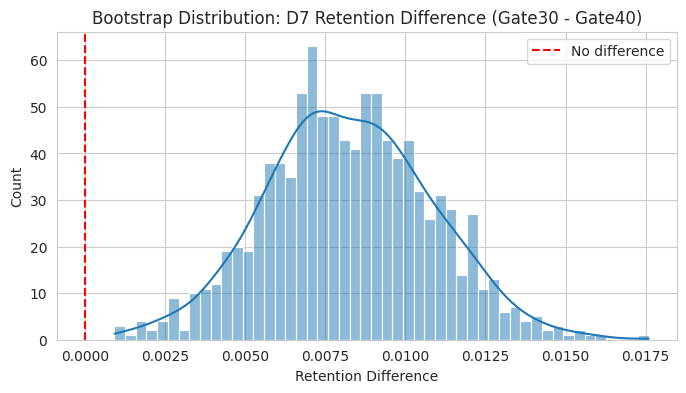

In [51]:
np.random.seed(42)
n_iterations = 1000
boot_diffs_d7 = []
boot_diffs_d1 = []

for i in range(n_iterations):
    sample = df.sample(frac=1, replace=True)
    r7 = sample.groupby('version')['retention_7'].mean()
    r1 = sample.groupby('version')['retention_1'].mean()
    boot_diffs_d7.append(r7['gate_30'] - r7['gate_40'])
    boot_diffs_d1.append(r1['gate_30'] - r1['gate_40'])

boot_diffs_d7 = np.array(boot_diffs_d7)
boot_diffs_d1 = np.array(boot_diffs_d1)

print("D7 diff — mean:", boot_diffs_d7.mean(),
      "95% CI:", np.percentile(boot_diffs_d7, [2.5, 97.5]))
print("D1 diff — mean:", boot_diffs_d1.mean(),
      "95% CI:", np.percentile(boot_diffs_d1, [2.5, 97.5]))
print("% of samples where gate_30 > gate_40 (D7):", (boot_diffs_d7 > 0).mean() * 100, "%")

# Visualize
plt.figure(figsize=(8,4))
sns.histplot(boot_diffs_d7, bins=50, kde=True)
plt.axvline(0, color='red', linestyle='--', label='No difference')
plt.title('Bootstrap Distribution: D7 Retention Difference (Gate30 - Gate40)')
plt.xlabel('Retention Difference')
plt.legend()
plt.show()

**Kết quả:** Chênh lệch D7 retention trung bình qua bootstrap = +0.82pp,
với 95% CI là [0.32pp, 1.34pp] — khoảng này hoàn toàn nằm phía dương (không
chứa 0), khớp với kết luận "có ý nghĩa thống kê" từ chi-square test. Ấn tượng
hơn nữa, 100% trong số 1000 mẫu bootstrap đều cho gate_30 > gate_40 — tức
gần như không có kịch bản resampling nào đảo ngược được kết luận.

Đây là bằng chứng mạnh hơn nhiều so với chỉ nhìn 1 p-value: không chỉ "có
khác biệt", mà khác biệt đó ổn định ở mức khoảng 0.3–1.3 điểm phần trăm,
nghiêng hẳn về gate_30.

#### 5.5 Sensitivity Analysis (loại outlier)

Đã ghi nhận ở mục 2 rằng có 1 user chơi tới 49,854 rounds — một giá trị bất thường có thể là bot hoặc lỗi tracking. Cần kiểm tra xem kết luận D7 có phụ thuộc vào riêng user này hay không, vì nếu có thì kết luận sẽ kém tin cậy hơn nhiều.

In [52]:
df_clean = df[df['sum_gamerounds'] < df['sum_gamerounds'].max()]
t7_clean = pd.crosstab(df_clean['version'], df_clean['retention_7'])
chi2_c, p_clean, _, _ = chi2_contingency(t7_clean)
d7_clean = df_clean.groupby('version')['retention_7'].mean() * 100

print("D7 retention (outlier removed):", d7_clean.to_dict())
print("p-value (outlier removed):", p_clean)

D7 retention (outlier removed): {'gate_30': 19.018322557551624, 'gate_40': 18.200004396667328}
p-value (outlier removed): 0.0016391259678654425


**Kết quả:** Sau khi loại outlier, D7 retention gần như không đổi (19.02%
vs 18.20%, p = 0.0016 — giống hệt kết quả gốc vì trên nền 90,189 user, 1
điểm dữ liệu không đủ sức thay đổi tỉ lệ tổng thể). Đây là bằng chứng cho
thấy kết luận D7 là robust — không bị "gánh" bởi một tài khoản bất thường
duy nhất, mà phản ánh xu hướng chung của toàn bộ user base.

#### 5.6 Multiple Testing Correction

Vì đã test đồng thời 2 giả thuyết độc lập (D1 và D7) trên cùng bộ dữ liệu, xác suất gặp ít nhất 1 false positive (kết luận nhầm là có ý nghĩa trong khi thực ra không) sẽ cao hơn so với chỉ test 1 giả thuyết. Bonferroni correction là cách đơn giản và bảo thủ (conservative) nhất để điều chỉnh lại ngưỡng ý nghĩa cho phù hợp.

In [53]:
p_values = [p1, p7]  # p-value của D1 và D7 đã tính ở mục 5.3
reject, p_corrected, _, _ = multipletests(p_values, alpha=0.05, method='bonferroni')

print("Corrected p-values:", p_corrected)
print("Still significant after correction:", reject)

Corrected p-values: [0.15100952 0.00320115]
Still significant after correction: [False  True]


**Kết quả:** Sau hiệu chỉnh Bonferroni, p-value của D7 tăng lên 0.0032
nhưng vẫn nhỏ hơn 0.05 → vẫn significant. D1 vẫn không significant như
trước. Kết luận không đổi ngay cả khi áp dụng phương pháp điều chỉnh bảo
thủ nhất — đây là một lớp kiểm chứng nữa củng cố độ tin cậy cho kết quả D7.

In [55]:
# Xuất stats_summary.csv để dùng cho Power BI
import numpy as np

ci_low, ci_high = np.percentile(boot_diffs_d7, [2.5, 97.5])

stats_summary = pd.DataFrame({
    'metric': ['D1_retention', 'D7_retention'],
    'gate_30': [d1['gate_30'], d7['gate_30']],
    'gate_40': [d1['gate_40'], d7['gate_40']],
    'diff_pp': [d1['gate_30'] - d1['gate_40'], d7['gate_30'] - d7['gate_40']],
    'ci_low': [None, ci_low * 100],
    'ci_high': [None, ci_high * 100],
    'p_value': [p1, p7],
    'significant': ['Yes' if p1 < 0.05 else 'No', 'Yes' if p7 < 0.05 else 'No']
})

stats_summary.to_csv('stats_summary.csv', index=False)
stats_summary

,metric,gate_30,gate_40,diff_pp,ci_low,ci_high,p_value,significant
0,D1_retention,44.818792,44.228275,0.590517,NaN,NaN,0.075505,No
1,D7_retention,19.020134,18.200004,0.820130,0.324896,1.335204,0.001601,Yes


### **6. Limitations & Assumptions**

**1. Sample Ratio Mismatch (p = 0.0086):**

Tỉ lệ chia nhóm lệch khỏi 50/50 có ý nghĩa thống kê (mục 5.1). Dataset có sẵn nên không truy được nguyên nhân gây SRM, vì vậy kết quả D7 nên hiểu là tín hiệu khá chắc chắn, không phải bằng chứng tuyệt đối.

**2. Không có timestamp:**

dataset không ghi thời điểm user tham gia, nên không đánh giá được novelty effect hay các yếu tố mùa vụ/ngày trong tuần.

**3. Không có dữ liệu doanh thu:**

monetization impact ở mục 7 chỉ là suy luận định tính dựa trên mối liên hệ chung giữa retention và LTV, chưa đo trực tiếp trên dataset này.

**4. 4.43% user chưa từng chơi round nào:**

Retention của nhóm này gần như bằng 0 ở cả 2 gate, đã kiểm tra ở mục 5.2 và không ảnh hưởng đến kết luận D7.


**5. Statistical vs practical significance:**

Chênh lệch D7 (+0.82pp, 95% CI 0.32–1.34pp) robust về mặt thống kê qua nhiều phép kiểm định, nhưng giá trị tuyệt đối vẫn khá nhỏ so với chi phí/độ phức tạp khi triển khai thực tế.

**6. Tương quan, không phải nhân quả tuyệt đối:**

A/B test giúp suy luận nhân quả tốt hơn quan sát thông thường, nhưng kết luận vẫn dựa trên 1 lần thử nghiệm duy nhất, chưa được lặp lại (replication) để xác nhận thêm.

### **7. Product Thinking & Recommendation**

**Business Insight**

D7 retention của gate_30 cao hơn gate_40 (19.02% vs 18.20%, +0.82pp). Kết quả này có ý nghĩa thống kê (chi-square p = 0.0016), 95% CI bootstrap không chứa 0 (+0.32pp đến +1.34pp), không đổi khi loại outlier, và vẫn giữ ý nghĩa sau Bonferroni correction (p = 0.0032). Ở D1, chênh lệch +0.59pp chưa đủ bằng chứng thống kê (p = 0.0755) — nên D7 là chỉ số dùng để quyết định.

**Product Interpretation**

- Gate ở level 30 tạo "điểm nghỉ" sớm hơn (thường đi kèm mời bạn bè hoặc chờ hồi), có thể giúp người chơi quay lại thay vì rời bỏ vì nhàm chán trước khi tới gate.

- Gate ở level 40 kéo dài quãng chơi liên tục trước điểm dừng — với nhóm Casual (74% user, mục 4), đây có thể là quãng đường quá dài khiến họ bỏ cuộc trước khi chạm gate.

**Monetization Impact**

Dataset không có dữ liệu doanh thu. D7 retention cao hơn thường đi kèm nhiều cơ hội quảng cáo và mua hàng trong app hơn, có thể cải thiện LTV — đây là suy luận định tính, chưa được kiểm chứng trực tiếp trên dataset này.

**Follow-up Experiments**

- Test gate_25 vs gate_30 để tìm điểm tối ưu sớm hơn.

- Test gate_30 kèm phần thưởng khi vượt gate, để tách tác động của vị trí gate và trải nghiệm tại gate.

- Test gate_30 với độ khó giảm nhẹ quanh gate, nhắm vào nhóm Casual (đông nhất và dễ rời bỏ nhất, mục 4).

**Recommendation**

Giữ gate ở level 30 thay vì chuyển sang level 40.
Kết luận dựa trên nhiều lớp kiểm chứng độc lập — chi-square test, bootstrap CI, sensitivity analysis, multiple testing correction — nên có độ tin cậy tương đối cao ở mốc D7. Lưu ý: (1) hiệu ứng tuyệt đối nhỏ (~0.82pp), nên giá trị chính nằm ở việc tránh một thay đổi có khả năng gây hại hơn là một cải tiến lớn; (2) giới hạn SRM ở mục 6 nghĩa là kết quả là tín hiệu đáng tin để tham khảo, không phải bằng chứng tuyệt đối.